# Used Car Price Prediction

**Data Science and Machine Learning Portfolio**  
**Student:** Shadrach Oboh  
**Student number:** C00298390  
**Assessment:** Data Science & Machine Learning Continuous Assessment (2026)

This portfolio investigates the factors associated with the selling prices of used cars. It also compares regression models that predict price from a vehicle's characteristics.

## Project aim and research questions

The aim is to complete the full data science process. This includes selecting and understanding a dataset, cleaning and transforming its fields, exploring important patterns, training reproducible machine learning models, validating them, and communicating the findings clearly.

The analysis addresses five questions:

1. How does a car's age relate to its selling price?
2. Do cars with more kilometres driven generally sell for less?
3. Are there price differences between fuel, transmission, and seller types?
4. Which available features are most useful to the prediction model?
5. Which of Linear Regression, Decision Tree Regression, and Random Forest Regression gives the best predictions?

The target is `selling_price`, measured in Indian rupees. The unit of analysis is a vehicle listing; observational relationships should not be interpreted as causal effects.

## 1. Setup and reproducibility

A fixed random seed is used for the data split, model validation, and model training. This makes the reported results reproducible when the same software versions and dataset are used. Figures are also saved to the `figures` directory for the presentation.

In [ ]:
# Shadrach Oboh (C00298390)
# Used Car Price Prediction portfolio

from pathlib import Path
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
DATA_PATH = Path("Car details v3.csv")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 110})

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

Python: 3.13.2
pandas: 3.1.0
scikit-learn: 1.9.1


## 2. Load and understand the dataset

The data is the **Vehicle Dataset from CarDekho**, published by Nehal Birla on Kaggle. The selected file is `Car details v3.csv`.

`skipinitialspace=True` is necessary because the supplied file contains padding spaces after commas. Column labels and text values are stripped to prevent visually identical categories with hidden spaces from being treated as different values.

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} was not found. Place it in the same folder as this notebook."
    )

raw_cars = pd.read_csv(DATA_PATH, skipinitialspace=True)
raw_cars.columns = raw_cars.columns.str.strip()

text_columns = raw_cars.select_dtypes(include=["object", "string"]).columns
raw_cars[text_columns] = raw_cars[text_columns].apply(lambda column: column.str.strip())

required_columns = {
    "name", "year", "selling_price", "km_driven", "fuel", "seller_type",
    "transmission", "owner", "mileage", "engine", "max_power", "torque", "seats"
}
assert required_columns.issubset(raw_cars.columns), "The CSV does not have the expected columns."
assert (raw_cars["selling_price"] > 0).all(), "Selling prices must be positive."

print(f"Dataset shape: {raw_cars.shape[0]:,} rows × {raw_cars.shape[1]} columns")
raw_cars.head()

Dataset shape: 8,128 rows × 13 columns


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.00
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.00
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.00
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.00
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.00


In [ ]:
raw_cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


### Data dictionary

| Field | Meaning | Initial type |
|---|---|---|
| `name` | Manufacturer and model description | Text |
| `year` | Vehicle model/registration year | Integer |
| `selling_price` | Advertised selling price (Indian rupees) | Integer |
| `km_driven` | Odometer reading in kilometres | Integer |
| `fuel` | Diesel, petrol, CNG, or LPG | Category |
| `seller_type` | Individual, dealer, or trustmark dealer | Category |
| `transmission` | Manual or automatic | Category |
| `owner` | Ownership history category | Category |
| `mileage` | Efficiency value stored with a unit | Text |
| `engine` | Engine displacement stored with `CC` | Text |
| `max_power` | Maximum power stored with `bhp` | Text |
| `torque` | Torque and engine speed description with mixed formatting | Text |
| `seats` | Number of seats | Numeric |

### Initial data quality audit

Missingness, duplicate rows, numerical summaries, and categorical values are checked before modifying the data. Exact duplicates must be identified before splitting; otherwise, an identical listing could occur in both the training and test sets and make performance look better than it really is.

In [ ]:
quality_summary = pd.DataFrame({
    "data_type": raw_cars.dtypes.astype(str),
    "missing_count": raw_cars.isna().sum(),
    "missing_percent": raw_cars.isna().mean().mul(100),
    "unique_values": raw_cars.nunique(dropna=True),
})

print(f"Exact duplicate rows: {raw_cars.duplicated().sum():,}")
display(quality_summary)
display(raw_cars.describe().T)

Exact duplicate rows: 1,202


,data_type,missing_count,missing_percent,unique_values
name,str,0,0.00,2058
year,int64,0,0.00,29
selling_price,int64,0,0.00,677
km_driven,int64,0,0.00,921
fuel,str,0,0.00,4
seller_type,str,0,0.00,3
transmission,str,0,0.00,2
owner,str,0,0.00,5
mileage,str,221,2.72,393
engine,str,221,2.72,121


,count,mean,std,min,25%,50%,75%,max
year,"8,128.00","2,013.80",4.04,"1,983.00","2,011.00","2,015.00","2,017.00","2,020.00"
selling_price,"8,128.00","638,271.81","806,253.40","29,999.00","254,999.00","450,000.00","675,000.00","10,000,000.00"
km_driven,"8,128.00","69,819.51","56,550.55",1.00,"35,000.00","60,000.00","98,000.00","2,360,457.00"
seats,"7,907.00",5.42,0.96,2.00,5.00,5.00,5.00,14.00


In [ ]:
for column in ["fuel", "seller_type", "transmission", "owner", "seats"]:
    print(f"\n{column}")
    display(raw_cars[column].value_counts(dropna=False).to_frame("count"))


fuel


,count
fuel,
Diesel,4402
Petrol,3631
CNG,57
LPG,38



seller_type


,count
seller_type,
Individual,6766
Dealer,1126
Trustmark Dealer,236



transmission


,count
transmission,
Manual,7078
Automatic,1050



owner


,count
owner,
First Owner,5289
Second Owner,2105
Third Owner,555
Fourth & Above Owner,174
Test Drive Car,5



seats


,count
seats,
5.00,6254
7.00,1120
8.00,236
NaN,221
4.00,133
9.00,80
6.00,62
10.00,19
2.00,2


## 3. Data cleaning and feature engineering

The following decisions are applied:

- **Exact duplicates:** removed before the train/test split to reduce leakage risk.
- **Car name:** the first word is retained as `brand`; the full name is dropped because individual model descriptions contain many unique and very similar values.
- **Year:** replaced with `car_age`. The reference year is fixed at one year after the newest vehicle in the dataset (2021), rather than using the computer's current year. This represents approximate age at the dataset period and keeps the calculation reproducible.
- **Mileage:** its number and unit are separated. `kmpl` and `km/kg` are not treated as the same unit; the unit is retained as a categorical feature.
- **Engine and power:** the first number is extracted and represented as cubic centimetres and brake horsepower.
- **Torque:** the first number is extracted. Values explicitly marked as kilogram force metres (`kgm` or `kg-m`) are converted to newton metres using 1 kgf·m = 9.80665 Nm. Ambiguous values without a stated `kgm` marker are treated as Nm.
- **Missing values:** retained at this stage. Median numerical imputation and the most common categorical value are fitted inside each model's training pipeline. This prevents information from the test set from influencing the preprocessing.

In [ ]:
def extract_first_number(series: pd.Series) -> pd.Series:
    '''Extract the first signed integer/decimal from a text Series.'''
    extracted = series.str.extract(r"([-+]?\d*\.?\d+)", expand=False)
    return pd.to_numeric(extracted, errors="coerce")


def engineer_car_features(data: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    '''Return a table with duplicates removed and features prepared for modelling.'''
    cleaned = data.drop_duplicates().copy()

    reference_year = int(cleaned["year"].max()) + 1
    cleaned["car_age"] = reference_year - cleaned["year"]
    cleaned["brand"] = cleaned["name"].str.split().str[0]

    cleaned["mileage_value"] = extract_first_number(cleaned["mileage"])
    cleaned["mileage_unit"] = cleaned["mileage"].str.extract(
        r"(kmpl|km/kg)", expand=False
    )
    cleaned["engine_cc"] = extract_first_number(cleaned["engine"])
    cleaned["max_power_bhp"] = extract_first_number(cleaned["max_power"])

    torque_value = extract_first_number(cleaned["torque"])
    torque_is_kgm = cleaned["torque"].str.lower().str.contains(
        r"kgm|kg-m", regex=True, na=False
    )
    cleaned["torque_nm"] = torque_value.where(
        ~torque_is_kgm, torque_value * 9.80665
    )

    return cleaned, reference_year


cars, REFERENCE_YEAR = engineer_car_features(raw_cars)

print(f"Rows before duplicate removal: {len(raw_cars):,}")
print(f"Exact duplicates removed: {len(raw_cars) - len(cars):,}")
print(f"Unique rows retained: {len(cars):,}")
print(f"Fixed reference year for car age: {REFERENCE_YEAR}")

Rows before duplicate removal: 8,128
Exact duplicates removed: 1,202
Unique rows retained: 6,926
Fixed reference year for car age: 2021


In [ ]:
engineered_columns = [
    "car_age", "brand", "mileage_value", "mileage_unit",
    "engine_cc", "max_power_bhp", "torque_nm", "seats"
]

cleaning_audit = pd.DataFrame({
    "data_type": cars[engineered_columns].dtypes.astype(str),
    "missing_count": cars[engineered_columns].isna().sum(),
    "missing_percent": cars[engineered_columns].isna().mean().mul(100),
    "unique_values": cars[engineered_columns].nunique(dropna=True),
})

display(cars[[
    "name", "year", "car_age", "mileage", "mileage_value", "mileage_unit",
    "engine", "engine_cc", "max_power", "max_power_bhp", "torque", "torque_nm"
]].head(10))
display(cleaning_audit)

,name,year,car_age,mileage,mileage_value,mileage_unit,engine,engine_cc,max_power,max_power_bhp,torque,torque_nm
0,Maruti Swift Dzire VDI,2014,7,23.4 kmpl,23.40,kmpl,1248 CC,"1,248.00",74 bhp,74.00,190Nm@ 2000rpm,190.00
1,Skoda Rapid 1.5 TDI Ambition,2014,7,21.14 kmpl,21.14,kmpl,1498 CC,"1,498.00",103.52 bhp,103.52,250Nm@ 1500-2500rpm,250.00
2,Honda City 2017-2020 EXi,2006,15,17.7 kmpl,17.70,kmpl,1497 CC,"1,497.00",78 bhp,78.00,"12.7@ 2,700(kgm@ rpm)",124.54
3,Hyundai i20 Sportz Diesel,2010,11,23.0 kmpl,23.00,kmpl,1396 CC,"1,396.00",90 bhp,90.00,22.4 kgm at 1750-2750rpm,219.67
4,Maruti Swift VXI BSIII,2007,14,16.1 kmpl,16.10,kmpl,1298 CC,"1,298.00",88.2 bhp,88.20,"11.5@ 4,500(kgm@ rpm)",112.78
5,Hyundai Xcent 1.2 VTVT E Plus,2017,4,20.14 kmpl,20.14,kmpl,1197 CC,"1,197.00",81.86 bhp,81.86,113.75nm@ 4000rpm,113.75
6,Maruti Wagon R LXI DUO BSIII,2007,14,17.3 km/kg,17.30,km/kg,1061 CC,"1,061.00",57.5 bhp,57.50,"7.8@ 4,500(kgm@ rpm)",76.49
7,Maruti 800 DX BSII,2001,20,16.1 kmpl,16.10,kmpl,796 CC,796.00,37 bhp,37.00,59Nm@ 2500rpm,59.00
8,Toyota Etios VXD,2011,10,23.59 kmpl,23.59,kmpl,1364 CC,"1,364.00",67.1 bhp,67.10,170Nm@ 1800-2400rpm,170.00
9,Ford Figo Diesel Celebration Edition,2013,8,20.0 kmpl,20.00,kmpl,1399 CC,"1,399.00",68.1 bhp,68.10,160Nm@ 2000rpm,160.00


,data_type,missing_count,missing_percent,unique_values
car_age,int64,0,0.00,29
brand,object,0,0.00,32
mileage_value,float64,208,3.00,381
mileage_unit,str,208,3.00,2
engine_cc,float64,208,3.00,121
max_power_bhp,float64,206,2.97,319
torque_nm,float64,209,3.02,251
seats,float64,208,3.00,9


## 4. Exploratory data analysis

Exploration is used to understand distributions and associations before modelling. Prices are strongly skewed to the right, so some visualisations use a logarithmic scale. This prevents a small number of luxury cars from compressing most observations. The models still predict the original price in rupees.

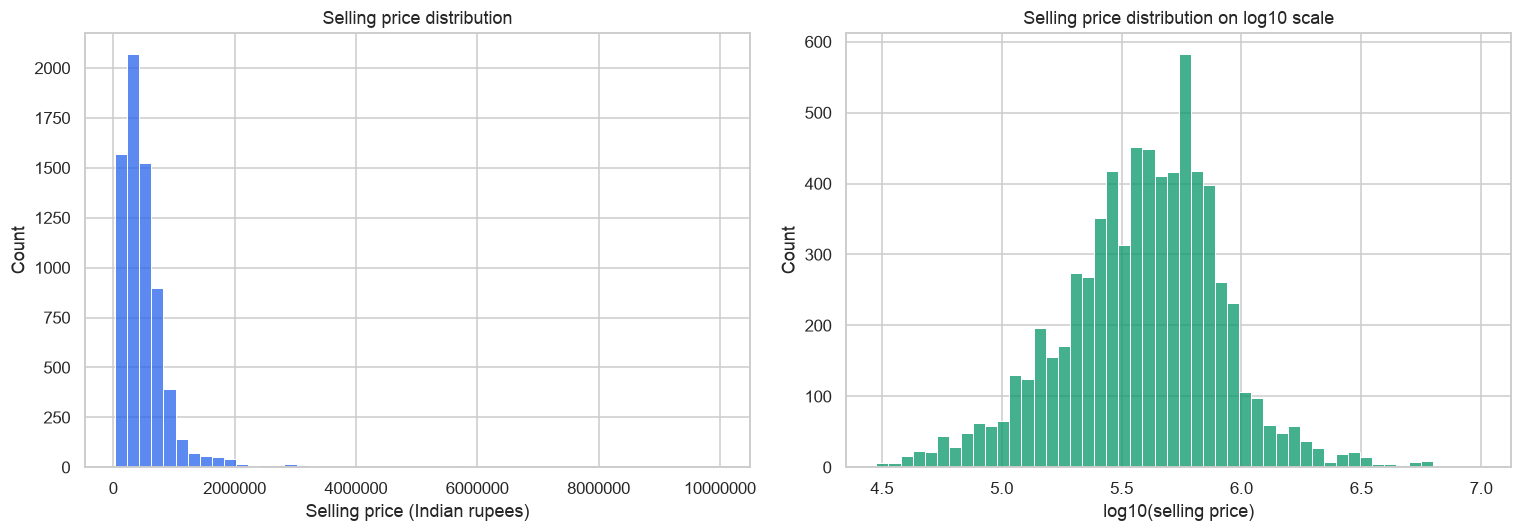

,selling_price
count,"6,926.00"
mean,"517,270.68"
std,"519,766.99"
min,"29,999.00"
90%,"900,000.00"
95%,"1,200,000.00"
99%,"2,708,250.00"
max,"10,000,000.00"


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(cars["selling_price"], bins=50, ax=axes[0], color="#2563eb")
axes[0].set_title("Selling price distribution")
axes[0].set_xlabel("Selling price (Indian rupees)")
axes[0].ticklabel_format(style="plain", axis="x")

sns.histplot(np.log10(cars["selling_price"]), bins=50, ax=axes[1], color="#059669")
axes[1].set_title("Selling price distribution on log10 scale")
axes[1].set_xlabel("log10(selling price)")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "price_distribution.png", bbox_inches="tight")
plt.show()

display(cars["selling_price"].describe(percentiles=[0.90, 0.95, 0.99]).to_frame())

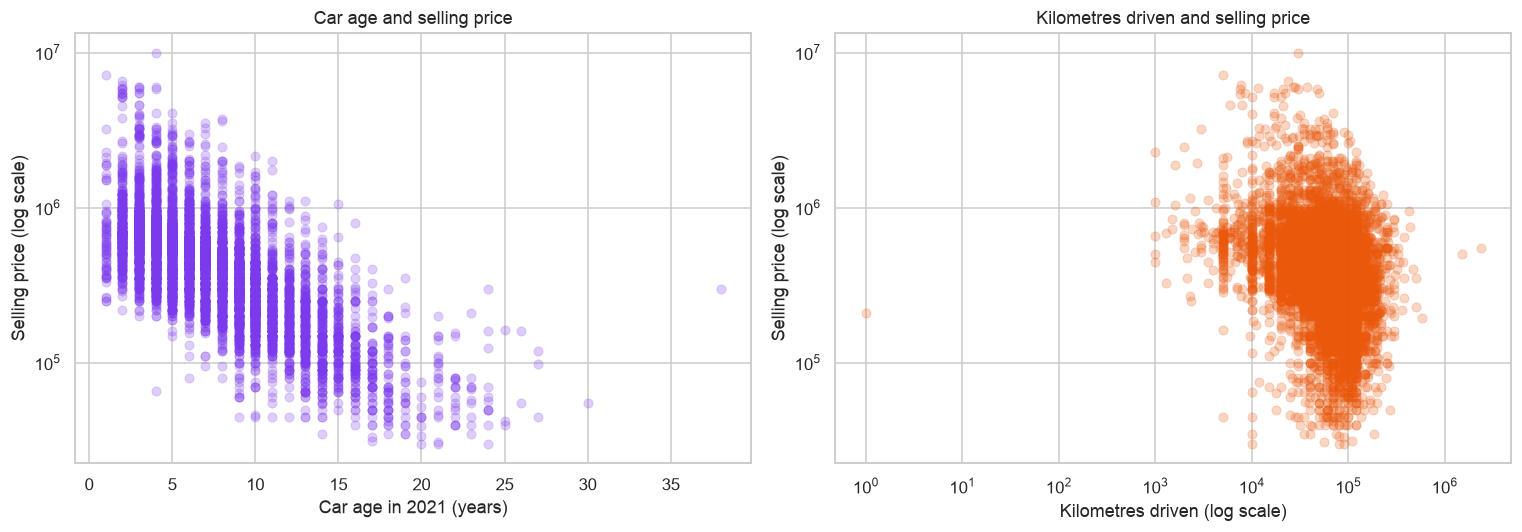

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=cars, x="car_age", y="selling_price", alpha=0.25,
    edgecolor=None, ax=axes[0], color="#7c3aed"
)
axes[0].set_yscale("log")
axes[0].set_title("Car age and selling price")
axes[0].set_xlabel(f"Car age in {REFERENCE_YEAR} (years)")
axes[0].set_ylabel("Selling price (log scale)")

sns.scatterplot(
    data=cars, x="km_driven", y="selling_price", alpha=0.25,
    edgecolor=None, ax=axes[1], color="#ea580c"
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Kilometres driven and selling price")
axes[1].set_xlabel("Kilometres driven (log scale)")
axes[1].set_ylabel("Selling price (log scale)")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "numerical_relationships.png", bbox_inches="tight")
plt.show()

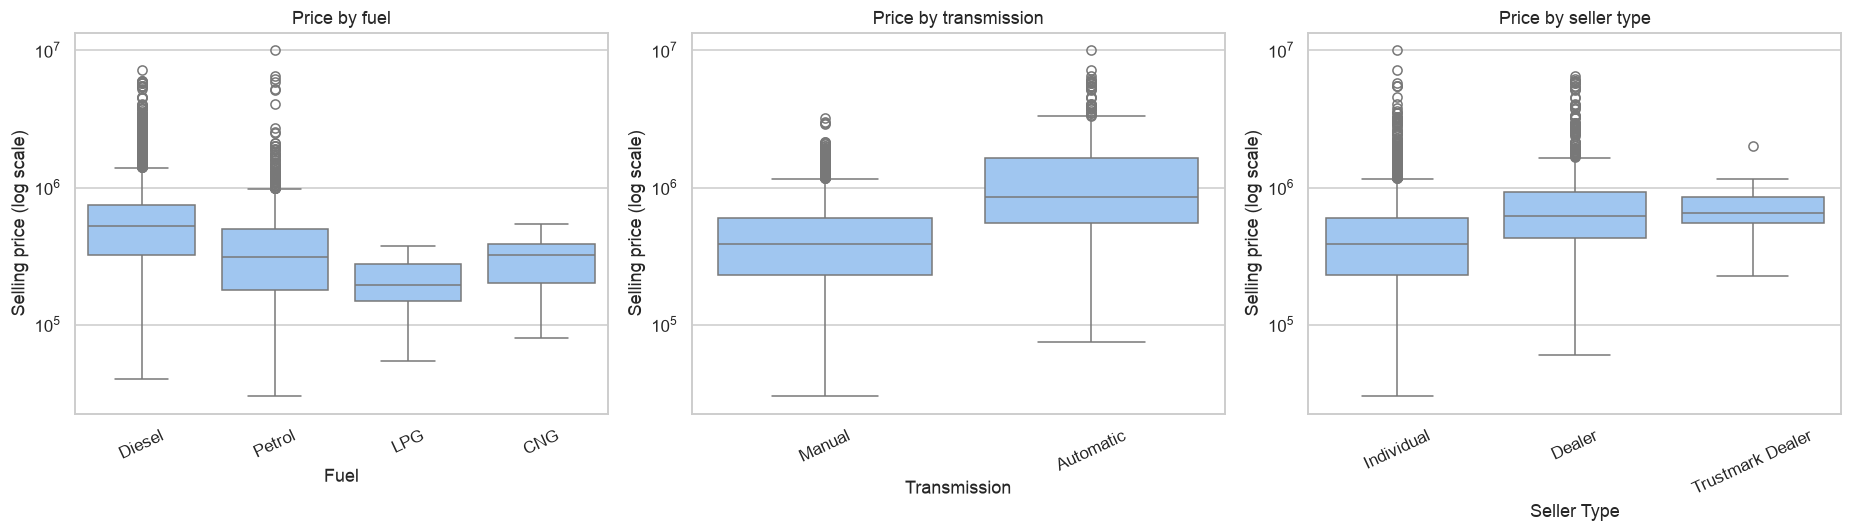

count     median         mean
feature      category                                       
fuel         CNG                  56 320,000.00   300,499.95
             Diesel             3755 520,000.00   639,727.77
             LPG                  38 195,500.00   200,421.05
             Petrol             3077 310,000.00   375,688.97
transmission Automatic           584 850,000.00 1,309,712.30
             Manual             6342 385,000.00   444,299.07
seller_type  Dealer              681 620,000.00   926,722.42
             Individual         6218 390,000.00   471,555.12
             Trustmark Dealer     27 650,000.00   718,111.11

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for axis, column, title in zip(
    axes,
    ["fuel", "transmission", "seller_type"],
    ["Price by fuel", "Price by transmission", "Price by seller type"],
):
    sns.boxplot(data=cars, x=column, y="selling_price", ax=axis, color="#93c5fd")
    axis.set_yscale("log")
    axis.set_title(title)
    axis.set_xlabel(column.replace("_", " ").title())
    axis.set_ylabel("Selling price (log scale)")
    axis.tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "categorical_prices.png", bbox_inches="tight")
plt.show()

category_summary = pd.concat(
    {
        column: cars.groupby(column)["selling_price"].agg(["count", "median", "mean"])
        for column in ["fuel", "transmission", "seller_type"]
    },
    names=["feature", "category"],
)
display(category_summary)

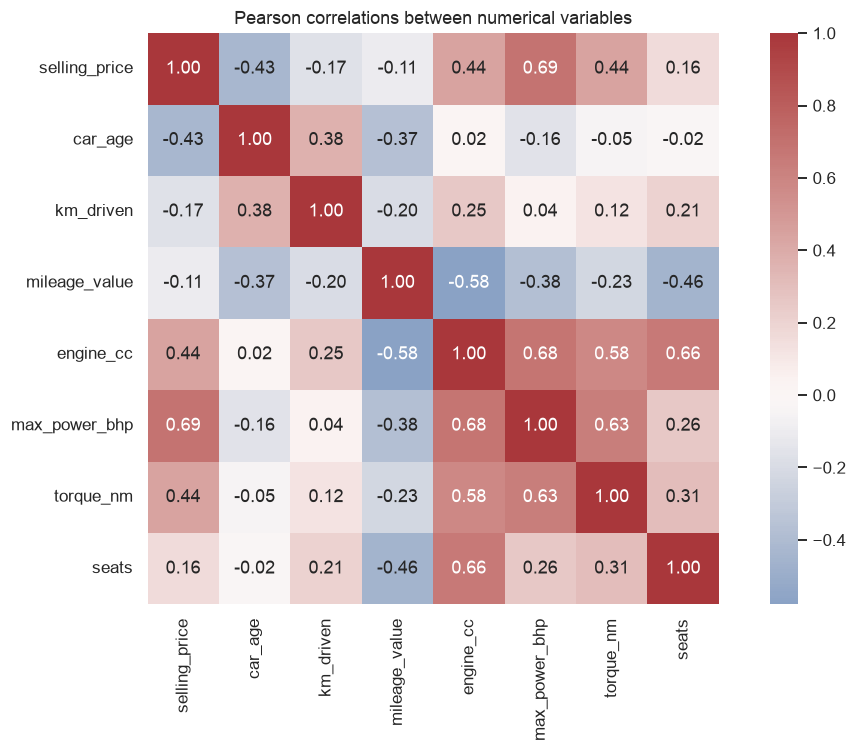

,correlation_with_selling_price
selling_price,1.00
max_power_bhp,0.69
torque_nm,0.44
engine_cc,0.44
seats,0.16
mileage_value,-0.11
km_driven,-0.17
car_age,-0.43


In [ ]:
eda_numeric_columns = [
    "selling_price", "car_age", "km_driven", "mileage_value",
    "engine_cc", "max_power_bhp", "torque_nm", "seats"
]
correlation_matrix = cars[eda_numeric_columns].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    correlation_matrix, annot=True, fmt=".2f", cmap="vlag",
    center=0, square=True, ax=ax
)
ax.set_title("Pearson correlations between numerical variables")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "correlation_heatmap.png", bbox_inches="tight")
plt.show()

correlation_with_price = correlation_matrix["selling_price"].sort_values(ascending=False)
display(correlation_with_price.to_frame("correlation_with_selling_price"))

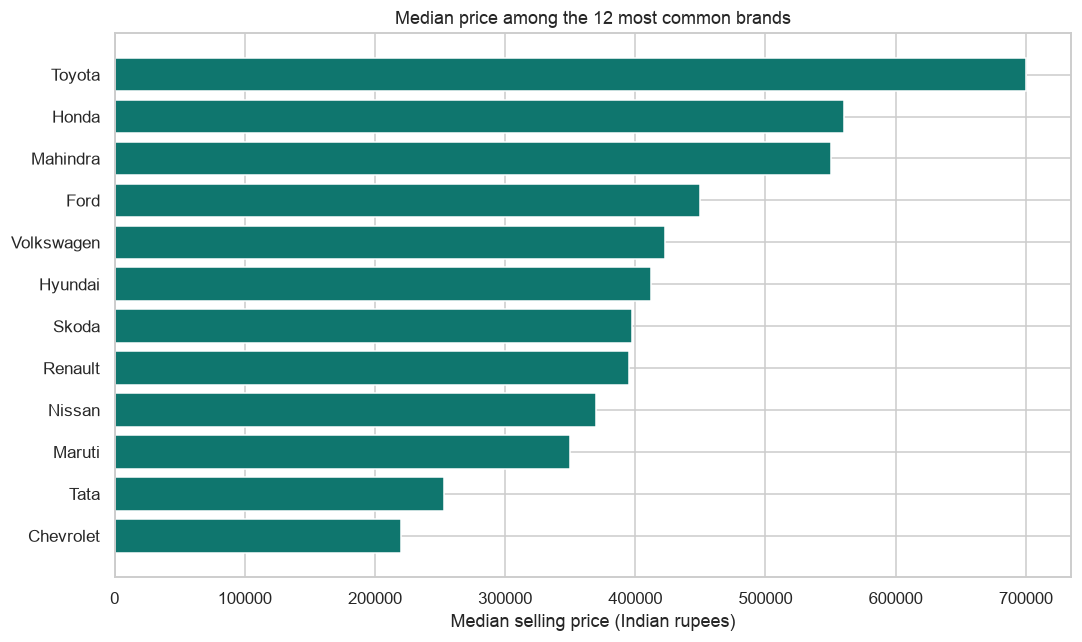

,count,median
brand,,
Toyota,357,"700,000.00"
Honda,362,"560,000.00"
Mahindra,723,"550,000.00"
Ford,361,"450,000.00"
Volkswagen,174,"422,500.00"
Hyundai,1267,"412,000.00"
Skoda,70,"397,500.00"
Renault,206,"395,000.00"
Nissan,73,"370,000.00"


In [ ]:
most_common_brands = cars["brand"].value_counts().head(12).index
brand_summary = (
    cars[cars["brand"].isin(most_common_brands)]
    .groupby("brand")["selling_price"]
    .agg(["count", "median"])
    .sort_values("median")
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(brand_summary.index, brand_summary["median"], color="#0f766e")
ax.set_title("Median price among the 12 most common brands")
ax.set_xlabel("Median selling price (Indian rupees)")
ax.ticklabel_format(style="plain", axis="x")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "brand_median_prices.png", bbox_inches="tight")
plt.show()

display(brand_summary.sort_values("median", ascending=False))

In [ ]:
age_correlation = cars[["car_age", "selling_price"]].corr().iloc[0, 1]
km_correlation = cars[["km_driven", "selling_price"]].corr().iloc[0, 1]

fuel_medians = cars.groupby("fuel")["selling_price"].median().sort_values(ascending=False)
transmission_medians = cars.groupby("transmission")["selling_price"].median().sort_values(ascending=False)
seller_medians = cars.groupby("seller_type")["selling_price"].median().sort_values(ascending=False)

display(Markdown(f'''
### Exploratory findings

- Car age has a **moderate negative** Pearson correlation with price ($r={age_correlation:.3f}$): older cars tend to be cheaper.
- Kilometres driven has a **weak negative** correlation with price ($r={km_correlation:.3f}$). Mileage matters, but the wide scatter indicates that age, brand, power, condition, and vehicle class also matter.
- Diesel vehicles have the highest median among the fuel groups with substantial sample sizes ({fuel_medians.get('Diesel', float('nan')):,.0f} rupees), compared with {fuel_medians.get('Petrol', float('nan')):,.0f} for petrol.
- Automatic vehicles have a median price of {transmission_medians.get('Automatic', float('nan')):,.0f} rupees, compared with {transmission_medians.get('Manual', float('nan')):,.0f} for manual vehicles.
- Dealer and trustmark listings have higher median prices than individual listings. These are **associations, not causal effects**: the groups contain different mixes of brands, ages, and vehicle classes.
'''))


### Exploratory findings

- Car age has a **moderate negative** Pearson correlation with price ($r=-0.433$): older cars tend to be cheaper.
- Kilometres driven has a **weak negative** correlation with price ($r=-0.166$). Mileage matters, but the wide scatter indicates that age, brand, power, condition, and vehicle class also matter.
- Diesel vehicles have the highest median among the fuel groups with substantial sample sizes (520,000 rupees), compared with 310,000 for petrol.
- Automatic vehicles have a median price of 850,000 rupees, compared with 385,000 for manual vehicles.
- Dealer and trustmark listings have higher median prices than individual listings. These are **associations, not causal effects**: the groups contain different mixes of brands, ages, and vehicle classes.


## 5. Machine learning design

### Features and target

The model uses seven numerical and six categorical predictors. The raw text fields are replaced by the engineered values described above. `selling_price` is the target.

### Leakage controls

1. Exact duplicates were removed before splitting.
2. A fixed 80/20 train/test split is created once.
3. Missing value imputation, scaling, and category encoding are contained in one preprocessing pipeline. They are fitted separately within each training fold.
4. Cross validation with five shuffled folds is performed on the training set only.
5. The test set is used once for final comparison.

The dummy median regressor is not a candidate model; it is a reference showing how much the trained models improve over always predicting the training median.

In [ ]:
numeric_features = [
    "car_age", "km_driven", "mileage_value", "engine_cc",
    "max_power_bhp", "torque_nm", "seats"
]
categorical_features = [
    "brand", "fuel", "seller_type", "transmission", "owner", "mileage_unit"
]
model_features = numeric_features + categorical_features

X = cars[model_features].copy()
y = cars["selling_price"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Predictor columns: {X.shape[1]}")

Training rows: 5,540
Test rows: 1,386
Predictor columns: 13


In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=RANDOM_STATE,
        min_samples_leaf=2,
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=1,
        max_features=1.0,
    ),
}

model_pipelines = {
    name: Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model),
    ])
    for name, model in models.items()
}

model_pipelines

{'Linear Regression': Pipeline(steps=[('preprocessor',
                  ColumnTransformer(transformers=[('numeric',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(strategy='median')),
                                                                   ('scaler',
                                                                    StandardScaler())]),
                                                   ['car_age', 'km_driven',
                                                    'mileage_value', 'engine_cc',
                                                    'max_power_bhp', 'torque_nm',
                                                    'seats']),
                                                  ('categorical',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(stra

### Evaluation measures

- **MAE (Mean Absolute Error):** average absolute difference between actual and predicted prices. Lower is better and it is easy to interpret in rupees.
- **RMSE (Root Mean Squared Error):** penalises large errors more strongly than MAE. Lower is better.
- **R²:** proportion of target variation explained relative to predicting the mean. Higher is better; 1 is perfect and values below 0 are worse than the mean reference.

MAE is the main practical measure, while RMSE reveals sensitivity to expensive mistakes and R² supports comparison of explained variation.

### Cross validation on the training set

Each model is trained five times on different parts of the training data. On each run, one part is reserved for validation. The mean and standard deviation summarise typical performance and stability without touching the final test set.

In [ ]:
cross_validator = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

cv_rows = []
for model_name, pipeline in model_pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cross_validator,
        scoring=scoring,
        n_jobs=1,
    )
    cv_rows.append({
        "Model": model_name,
        "CV MAE mean": -scores["test_MAE"].mean(),
        "CV MAE std": scores["test_MAE"].std(),
        "CV RMSE mean": -scores["test_RMSE"].mean(),
        "CV RMSE std": scores["test_RMSE"].std(),
        "CV R2 mean": scores["test_R2"].mean(),
        "CV R2 std": scores["test_R2"].std(),
    })

cv_summary = pd.DataFrame(cv_rows).sort_values("CV RMSE mean").reset_index(drop=True)
display(cv_summary.style.format({
    "CV MAE mean": "{:,.0f}",
    "CV MAE std": "{:,.0f}",
    "CV RMSE mean": "{:,.0f}",
    "CV RMSE std": "{:,.0f}",
    "CV R2 mean": "{:.3f}",
    "CV R2 std": "{:.3f}",
}))

,Model,CV MAE mean,CV MAE std,CV RMSE mean,CV RMSE std,CV R2 mean,CV R2 std
0,Random Forest,"81,224","3,367","172,946","24,903",0.889,0.030
1,Decision Tree,"101,927","8,409","244,277","44,165",0.778,0.079
2,Linear Regression,"139,933","8,946","274,506","41,382",0.728,0.037


### Final test set evaluation

The candidate pipelines are fitted to all training rows and evaluated on the untouched test set. A median dummy baseline is included for context.

In [ ]:
test_rows = []
fitted_pipelines = {}

dummy_model = DummyRegressor(strategy="median")
dummy_model.fit(np.zeros((len(y_train), 1)), y_train)
dummy_predictions = dummy_model.predict(np.zeros((len(y_test), 1)))
test_rows.append({
    "Model": "Median Baseline",
    "MAE": mean_absolute_error(y_test, dummy_predictions),
    "RMSE": root_mean_squared_error(y_test, dummy_predictions),
    "R2": r2_score(y_test, dummy_predictions),
})

for model_name, pipeline in model_pipelines.items():
    fitted_pipeline = pipeline.fit(X_train, y_train)
    predictions = fitted_pipeline.predict(X_test)
    fitted_pipelines[model_name] = fitted_pipeline
    test_rows.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R2": r2_score(y_test, predictions),
    })

test_results = pd.DataFrame(test_rows)
display(test_results.style.format({
    "MAE": "{:,.0f}",
    "RMSE": "{:,.0f}",
    "R2": "{:.3f}",
}))

,Model,MAE,RMSE,R2
0,Median Baseline,"259,547","478,963",-0.046
1,Linear Regression,"132,934","261,726",0.688
2,Decision Tree,"86,250","151,591",0.895
3,Random Forest,"72,162","124,031",0.930


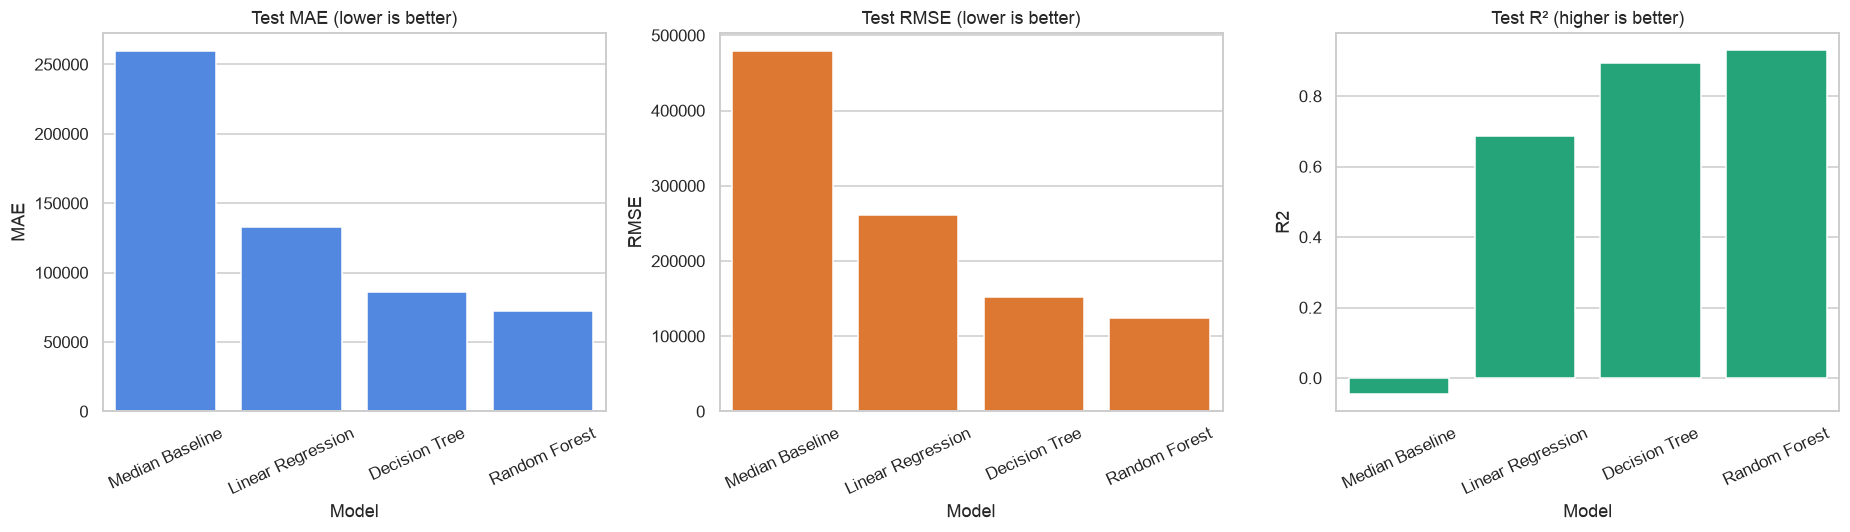

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=test_results, x="Model", y="MAE", ax=axes[0], color="#3b82f6")
sns.barplot(data=test_results, x="Model", y="RMSE", ax=axes[1], color="#f97316")
sns.barplot(data=test_results, x="Model", y="R2", ax=axes[2], color="#10b981")

axes[0].set_title("Test MAE (lower is better)")
axes[1].set_title("Test RMSE (lower is better)")
axes[2].set_title("Test R² (higher is better)")
for axis in axes:
    axis.tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_comparison.png", bbox_inches="tight")
plt.show()

In [ ]:
best_model_name = cv_summary.iloc[0]["Model"]
best_pipeline = fitted_pipelines[best_model_name]
best_predictions = best_pipeline.predict(X_test)
best_test_row = test_results.loc[test_results["Model"] == best_model_name].iloc[0]
best_cv_row = cv_summary.loc[cv_summary["Model"] == best_model_name].iloc[0]
baseline_row = test_results.loc[test_results["Model"] == "Median Baseline"].iloc[0]
mae_improvement = 100 * (baseline_row["MAE"] - best_test_row["MAE"]) / baseline_row["MAE"]

display(Markdown(f'''
### Model comparison

**{best_model_name}** was selected using the lowest mean validation RMSE. The test set was not used to choose the model. Across the training folds it achieved mean MAE of **{best_cv_row['CV MAE mean']:,.0f} rupees**, mean RMSE of **{best_cv_row['CV RMSE mean']:,.0f} rupees**, and mean R² of **{best_cv_row['CV R2 mean']:.3f}**.

On the untouched test set it achieved:

- **MAE:** {best_test_row['MAE']:,.0f} rupees
- **RMSE:** {best_test_row['RMSE']:,.0f} rupees
- **R²:** {best_test_row['R2']:.3f}

Its MAE is **{mae_improvement:.1f}% lower** than the median price baseline. RMSE is higher than MAE because a relatively small number of expensive vehicles produce large absolute errors.
'''))


### Model comparison

**Random Forest** was selected using the lowest mean validation RMSE. The test set was not used to choose the model. Across the training folds it achieved mean MAE of **81,224 rupees**, mean RMSE of **172,946 rupees**, and mean R² of **0.889**.

On the untouched test set it achieved:

- **MAE:** 72,162 rupees
- **RMSE:** 124,031 rupees
- **R²:** 0.930

Its MAE is **72.2% lower** than the median price baseline. RMSE is higher than MAE because a relatively small number of expensive vehicles produce large absolute errors.


## 6. Diagnostics for the best model

The plot of actual and predicted values checks overall agreement. Both axes use logarithmic scales because prices span more than two orders of magnitude. The residual plot checks whether prediction errors are centred around zero and shows how error size changes with predicted price.

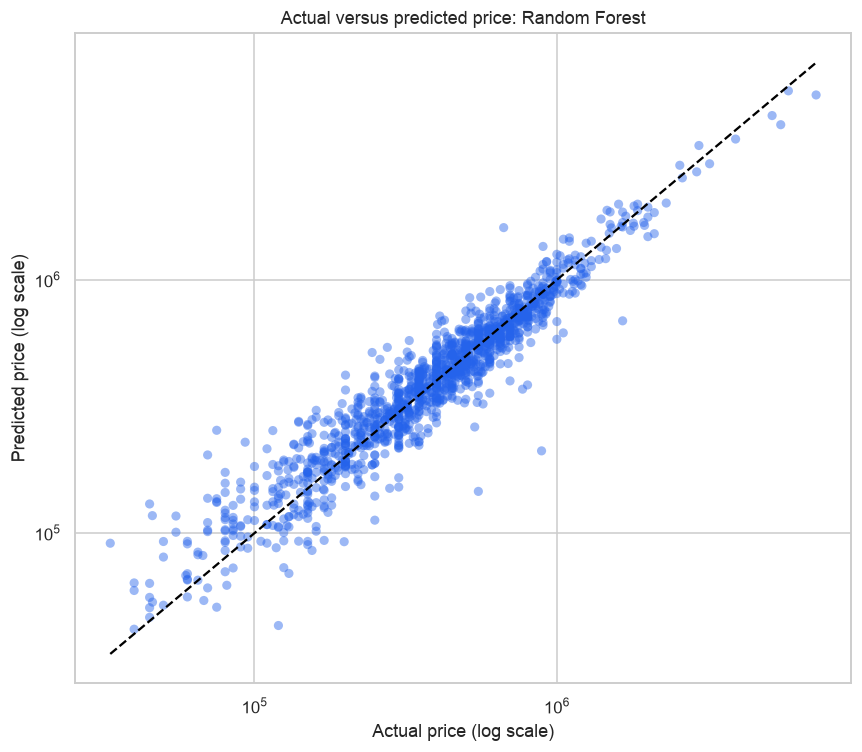

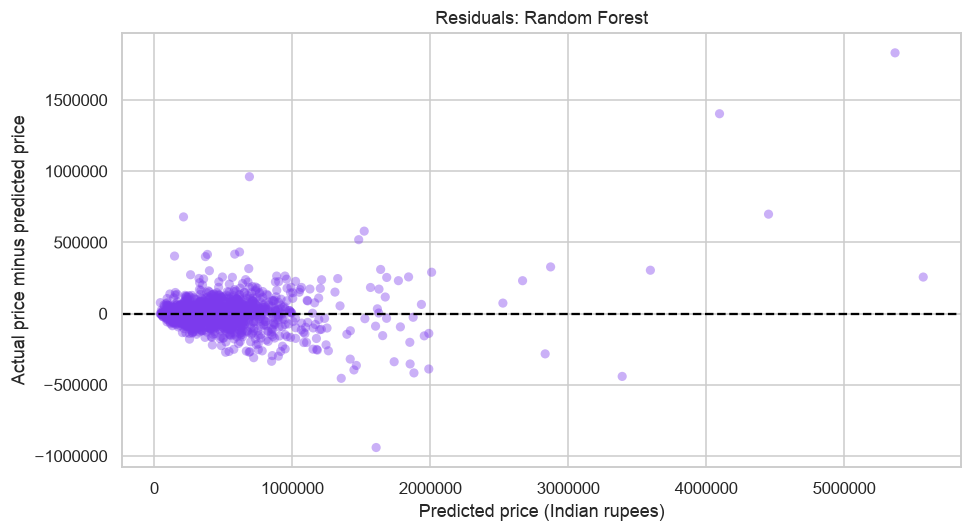

,residual
count,"1,386.00"
mean,290.98
std,"124,075.31"
min,"-940,594.99"
25%,"-49,984.49"
50%,"-3,852.54"
75%,"44,419.69"
max,"1,830,728.33"


In [ ]:
residuals = y_test.to_numpy() - best_predictions
minimum_price = min(y_test.min(), best_predictions.min())
maximum_price = max(y_test.max(), best_predictions.max())

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(y_test, best_predictions, alpha=0.45, color="#2563eb", edgecolor="none")
ax.plot([minimum_price, maximum_price], [minimum_price, maximum_price], "--", color="black")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title(f"Actual versus predicted price: {best_model_name}")
ax.set_xlabel("Actual price (log scale)")
ax.set_ylabel("Predicted price (log scale)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "actual_vs_predicted.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(best_predictions, residuals, alpha=0.4, color="#7c3aed", edgecolor="none")
ax.axhline(0, linestyle="--", color="black")
ax.set_title(f"Residuals: {best_model_name}")
ax.set_xlabel("Predicted price (Indian rupees)")
ax.set_ylabel("Actual price minus predicted price")
ax.ticklabel_format(style="plain", axis="both")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "residuals.png", bbox_inches="tight")
plt.show()

display(pd.Series(residuals, name="residual").describe().to_frame())

### Feature importance

Importance from the fitted random forest is used to describe which inputs the model used most. Encoded columns belonging to the same original category are added together. This association is specific to this model. It does not prove that changing a feature would cause a price change. The measure may also favour continuous variables or fields with many distinct values, so it is interpreted alongside the exploratory analysis.

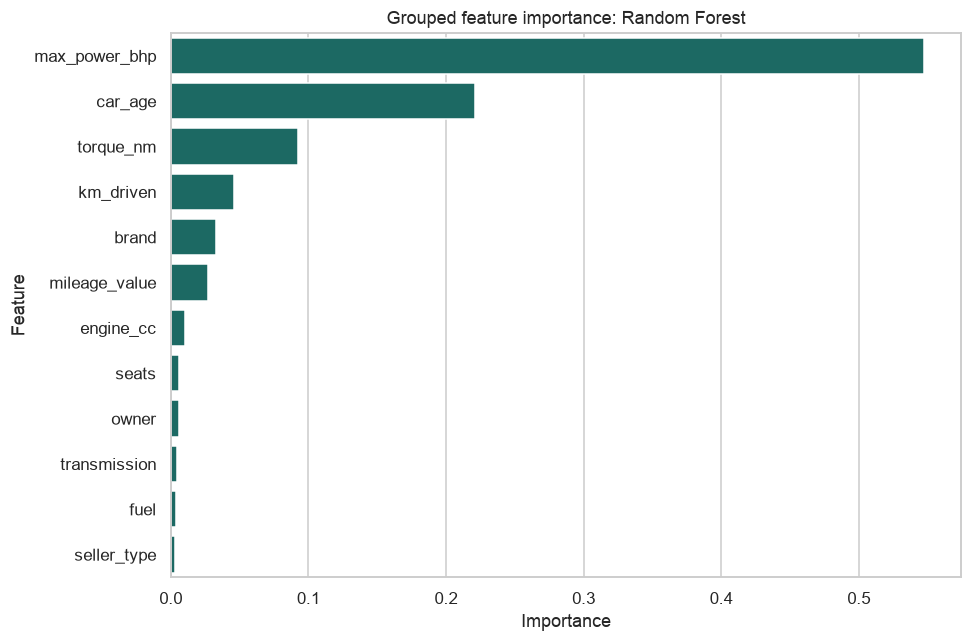

,Feature,Importance
5,max_power_bhp,0.547
1,car_age,0.221
11,torque_nm,0.093
4,km_driven,0.046
0,brand,0.033
7,mileage_value,0.027
2,engine_cc,0.010
9,seats,0.006
8,owner,0.006
12,transmission,0.005


In [ ]:
if not hasattr(best_pipeline.named_steps["model"], "feature_importances_"):
    raise TypeError("The selected model does not expose tree feature importance.")

transformed_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
transformed_importance = best_pipeline.named_steps["model"].feature_importances_


def original_feature_name(transformed_name: str) -> str:
    '''Map a transformed ColumnTransformer name back to its source feature.'''
    clean_name = transformed_name.split("__", maxsplit=1)[-1]
    for feature in categorical_features:
        if clean_name == feature or clean_name.startswith(f"{feature}_"):
            return feature
    return clean_name


feature_importance = (
    pd.DataFrame({
        "Feature": [original_feature_name(name) for name in transformed_names],
        "Importance": transformed_importance,
    })
    .groupby("Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(
    data=feature_importance.head(12),
    x="Importance",
    y="Feature",
    ax=ax,
    color="#0f766e",
)
ax.set_title(f"Grouped feature importance: {best_model_name}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_importance.png", bbox_inches="tight")
plt.show()

display(feature_importance.style.format({"Importance": "{:.3f}"}))

In [ ]:
prediction_examples = X_test.copy()
prediction_examples["Actual price"] = y_test
prediction_examples["Predicted price"] = best_predictions
prediction_examples["Absolute error"] = np.abs(
    prediction_examples["Actual price"] - prediction_examples["Predicted price"]
)

display(
    prediction_examples[
        ["brand", "car_age", "km_driven", "fuel", "transmission",
         "Actual price", "Predicted price", "Absolute error"]
    ]
    .sample(10, random_state=RANDOM_STATE)
    .sort_values("Actual price")
    .style.format({
        "Actual price": "{:,.0f}",
        "Predicted price": "{:,.0f}",
        "Absolute error": "{:,.0f}",
    })
)

,brand,car_age,km_driven,fuel,transmission,Actual price,Predicted price,Absolute error
3647,Hyundai,15,80000,Petrol,Manual,"70,000","137,278","67,278"
2649,Hyundai,10,50000,Petrol,Manual,"170,000","180,350","10,350"
1172,Hyundai,7,65000,Petrol,Manual,"300,000","340,130","40,130"
7138,Maruti,3,15000,Petrol,Manual,"320,000","311,494","8,506"
669,Fiat,8,90000,Diesel,Manual,"400,000","328,395","71,605"
6372,Hyundai,4,70000,Petrol,Manual,"450,000","586,584","136,584"
7798,Tata,7,78000,Diesel,Manual,"525,000","622,427","97,427"
6943,Maruti,7,88000,Diesel,Manual,"580,000","502,244","77,756"
4546,Maruti,5,90000,Diesel,Manual,"620,000","768,600","148,600"
4574,Mahindra,3,22000,Diesel,Manual,"750,000","618,753","131,247"


## 7. Conclusions

In [ ]:
top_features = ", ".join(feature_importance.head(4)["Feature"].tolist())

display(Markdown(f'''
### Answers to the research questions

1. **How does age affect price?** Car age and selling price have a moderate negative correlation ($r={age_correlation:.3f}$). The scatter plot and the high model importance for `car_age` both indicate that older vehicles generally sell for less, although age does not determine price by itself.

2. **Do cars with more kilometres sell for less?** The relationship is negative but weak ($r={km_correlation:.3f}$). The model uses kilometres driven, but its importance is below power and age. This suggests that an odometer reading must be interpreted together with vehicle type, age, and specification.

3. **Are there categorical price differences?** Yes. Automatic vehicles, diesel vehicles, and cars listed by dealers have higher observed median prices than their comparison groups. These differences are descriptive and may reflect the mix of luxury brands, vehicle ages, and specifications within each group.

4. **Which features matter most?** The leading grouped features in the random forest are **{top_features}**. Maximum power and age are especially influential in this fitted model.

5. **Which model predicts best?** Based on training validation across five folds, **{best_model_name}** performs best. Its final test MAE is **{best_test_row['MAE']:,.0f} rupees**, RMSE is **{best_test_row['RMSE']:,.0f} rupees**, and R² is **{best_test_row['R2']:.3f}**. It substantially improves on the median baseline and outperforms Linear Regression and the individual Decision Tree.

### Overall conclusion

The portfolio demonstrates a reproducible route from a raw CSV file containing numeric and text fields to a validated regression model. The Random Forest is more suitable than the linear baseline because vehicle pricing reflects complex relationships among age, power, brand, use, and market segment. The model is useful for approximate price estimates within the represented CarDekho market, but it should not be treated as a universal valuation tool.
'''))


### Answers to the research questions

1. **How does age affect price?** Car age and selling price have a moderate negative correlation ($r=-0.433$). The scatter plot and the high model importance for `car_age` both indicate that older vehicles generally sell for less, although age does not determine price by itself.

2. **Do cars with more kilometres sell for less?** The relationship is negative but weak ($r=-0.166$). The model uses kilometres driven, but its importance is below power and age. This suggests that an odometer reading must be interpreted together with vehicle type, age, and specification.

3. **Are there categorical price differences?** Yes. Automatic vehicles, diesel vehicles, and cars listed by dealers have higher observed median prices than their comparison groups. These differences are descriptive and may reflect the mix of luxury brands, vehicle ages, and specifications within each group.

4. **Which features matter most?** The leading grouped features in the random forest are **max_power_bhp, car_age, torque_nm, km_driven**. Maximum power and age are especially influential in this fitted model.

5. **Which model predicts best?** Based on training validation across five folds, **Random Forest** performs best. Its final test MAE is **72,162 rupees**, RMSE is **124,031 rupees**, and R² is **0.930**. It substantially improves on the median baseline and outperforms Linear Regression and the individual Decision Tree.

### Overall conclusion

The portfolio demonstrates a reproducible route from a raw CSV file containing numeric and text fields to a validated regression model. The Random Forest is more suitable than the linear baseline because vehicle pricing reflects complex relationships among age, power, brand, use, and market segment. The model is useful for approximate price estimates within the represented CarDekho market, but it should not be treated as a universal valuation tool.


## 8. Limitations, ethics, and future work

### Limitations

- The dataset represents listings from one platform and market period; prices may not generalise to Ireland, other countries, or later years.
- The dataset does not document sale completion, exact listing date, location, accident history, service history, trim consistency, or vehicle condition.
- `name` is simplified to the first word, which represents the brand. Detailed model and trim information could improve prediction if cleaned carefully.
- Torque formatting is inconsistent. The conversion handles explicit `kgm` values but assumes ambiguous unmarked values are Nm.
- Mileage uses both `kmpl` and `km/kg`. Their units are retained, but they are not physically converted to a common measure of energy efficiency.
- The price distribution contains rare luxury vehicles and extreme odometer values. These may be real, but they increase RMSE and make predictions less reliable at the extremes.
- Feature importance describes the fitted model and can be biased; it does not establish causation.

### Ethical considerations

- A price estimate could disadvantage a buyer or seller if presented as a guaranteed valuation. Predictions should include context and human review.
- Platform data may reflect existing market biases between brands, fuel types, locations, and seller categories.
- No personally identifying information is used in this dataset.

### Future improvements

1. Obtain location, condition, model/trim, and listing date features.
2. Compare gradient boosting and tuned ensembles using nested or repeated cross validation.
3. Test the logarithm of price as a target and check whether it improves relative error without harming interpretation.
4. Use permutation importance or SHAP values to examine feature effects more robustly.
5. Validate the final model on a newer, independently collected dataset.

## 9. Infrastructure and reproducibility notes

- **Storage:** the raw CSV, executed notebook, exported HTML, figures, requirements file, and diary are stored together in the portfolio folder. The original CSV is retained unchanged.
- **Processing:** Python and Jupyter provide a clear sequence of code, output, charts, and reasoning that can be checked.
- **Reproducibility:** fixed seeds, an isolated `.venv`, a requirements file, and one complete pipeline reduce differences in the environment and preprocessing.
- **Backups:** the portfolio folder is stored in the student's institutional OneDrive. A second copy or a repository with version control is recommended before submission.

In [ ]:
print("Final validation checks")
print(f"Raw rows: {len(raw_cars):,}")
print(f"Unique analysed rows: {len(cars):,}")
print(f"Training/test rows: {len(X_train):,}/{len(X_test):,}")
print(f"Selected model: {best_model_name}")
print(f"Saved figures: {len(list(FIGURE_DIR.glob('*.png')))}")

assert len(X_train) + len(X_test) == len(cars)
assert not set(X_train.index).intersection(set(X_test.index))
assert np.isfinite(best_predictions).all()
assert len(best_predictions) == len(y_test)
print("All checks passed.")

Final validation checks
Raw rows: 8,128
Unique analysed rows: 6,926
Training/test rows: 5,540/1,386
Selected model: Random Forest
Saved figures: 9
All checks passed.


## 10. References

1. Birla, N. **Vehicle Dataset from CarDekho**. Kaggle. https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho
2. pandas documentation. **`pandas.read_csv`**. https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
3. scikit-learn documentation. **Pipelines and composite estimators**. https://scikit-learn.org/stable/modules/compose.html
4. scikit-learn documentation. **`train_test_split`**. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
5. scikit-learn documentation. **`cross_validate`**. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html
6. scikit-learn documentation. **`RandomForestRegressor`**. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html
7. scikit-learn documentation. **Regression model evaluation**. https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics
8. Matplotlib documentation. https://matplotlib.org/stable/

